### Kacheln – Lösung Schritt für Schritt

*Jugendwettbewerb Informatik 2019, 3. Runde, Junioraufgabe 2 (= 38. Bundeswettbewerb Informatik, 1. Runde, Junioraufgabe 2)*

Für ein Computerspiel sollen zweidimensionale Landschaften aus quadratischen Kacheln zusammengesetzt werden. Hierzu sind die
16 Kacheln vorgegeben (siehe Ordner `beispieldaten/kacheln`), von denen jede beliebig oft verwendet werden kann. Die Kacheln müssen nicht
gedreht werden.

Die Kacheln sind so gestaltet, dass man jede in vier Quadrate aufteilen kann, deren Außenseiten entweder nur Wasser oder
nur Land aufweisen. Damit die Landschaft natürlich aussieht, dürfen die Kacheln nur so aneinander gelegt werden, dass Land
auf Land und Wasser auf Wasser trifft.

Damit Landschaften durch einen Computer generiert werden können, werden die Quadrate durch Bits und die Kacheln als
2x2-Bitmuster repräsentiert: 1 steht für ein Quadrat mit Land und 0 für ein Quadrat mit Wasser an den Außenseiten.

In dieser Aufgabe sollen nun unvollständige Landschaften vervollständigt werden.

#### Junioraufgabe 2

Schreibe ein Programm, das eine unvollständige Landschaft einliest und unter Beachtung der obigen Regeln zu einer
vollständigen Landschaft ergänzt. Selbst wenn unterschiedliche Ergänzungen möglich sind, soll nur eine vollständige
Landschaft ausgegeben werden. Wenn eine Ergänzung ohne Regelverletzung gar nicht möglich ist, soll dies erkannt und
angezeigt werden.

Wende dein Programm auf alle Beispiele an, die sich auf der BWINF-Website befinden. Dort sind auch die Kacheln und weitere
Hinweise zu finden.

#### Beispieldaten

- `map_spacy.txt` (das Beispiel vom Aufgabenblatt, 2 × 2 Kacheln) und `map1_spacy.txt` bis `map5_spacy.txt`: 1. Zeile Anzahl der
  Kachelreihen, 2. Zeile Anzahl der Kachelspalten, eine Leerzeile, dann die Karte: je Kachel 2 × 2 Zeichen `0` (Wasser),
  `1` (Land) oder `*` (unbekannt)
- `map*_compact.txt`: dieselben Karten ohne Leer- und Trennzeichen
- `kacheln/`: Bilder der 16 Kacheln (der Dateiname enthält das Bitmuster, zum Beispiel `tile1_0001.png`)

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Zweidimensionales Raster:** Die Karte ist eine Liste von Zeilen, jede Zeile eine Liste von Zeichen. `karte[z][s]` ist das Quadrat in Zeile `z` und Spalte `s`.
- **Zusammenhangskomponenten (Flood Fill, Tiefensuche):** Quadrate, die gleich sein müssen, bilden eine Gruppe. Man sammelt eine Gruppe, indem man von einem
  Quadrat aus alle verbundenen Nachbarn besucht (mit einer Liste als Stapel). Aus der Graphentheorie: Das sind die Zusammenhangskomponenten eines Graphen.
- **Einschränkungen (Constraints) erfüllen:** Jede Gruppe hat eine Farbe (Wasser oder Land). Kommen in einer Gruppe beide Farben vor, gibt es keine Lösung.
- **Überprüfen des Ergebnisses:** Eine eigene Prüffunktion stellt sicher, dass das Ergebnis alle Regeln erfüllt.
- **Alternativen:** Backtracking (rekursives Ausprobieren) oder Union-Find (eine Datenstruktur für Gruppen) funktionieren auch, sind aber für diese Aufgabe nicht nötig.

**Nützliche Funktionen und Bibliotheken**
- Strings und Listen: `split()`, `''.join(...)`, `list(text)`, `set`, `in`
- Für die Bilder: **Pillow** (`PIL.Image`) und **matplotlib** (optional, nur zum Anzeigen)

## Die Idee

Jede Kachel besteht aus vier Quadraten (oben links, oben rechts, unten links, unten rechts). Liegen zwei Kacheln nebeneinander, müssen sich die
Quadrate an der gemeinsamen Kante entsprechen: Das Quadrat rechts oben der linken Kachel muss dieselbe Farbe haben wie das Quadrat links oben der rechten Kachel, und
rechts unten wie links unten. Ebenso bei Kacheln übereinander.

Wir stellen die Karte als Raster aus **Quadraten** dar (doppelt so viele Zeilen und Spalten wie Kacheln). Dann gilt:

- Ein Quadrat in der Spalte `s` hat einen **waagerechten Partner**, wenn es am rechten oder linken Rand seiner Kachel liegt und dort eine andere Kachel anschließt:
  ist `s` ungerade (rechtes Quadrat einer Kachel), ist der Partner in Spalte `s + 1`, ist `s` gerade (linkes Quadrat), ist der Partner in Spalte `s − 1`.
  Am Rand der Karte gibt es keinen Partner.
- Genauso gibt es einen **senkrechten Partner** (Zeile `z + 1` bei ungeradem `z`, Zeile `z − 1` bei geradem `z`).

Jedes Quadrat hat also höchstens zwei Partner. Partner müssen gleich sein, und die Partner der Partner auch. So entstehen **Gruppen** aus 1, 2 oder 4 Quadraten
(in den Ecken der Karte 1, am Rand 2, innen 4), die alle dieselbe Farbe bekommen müssen.

Das Verfahren:
1. Gruppen bilden.
2. In jeder Gruppe nachsehen, welche Farben schon bekannt sind. Kommen `0` und `1` vor, ist die Landschaft **nicht lösbar**.
3. Sonst alle Quadrate der Gruppe mit der bekannten Farbe füllen (oder mit `0`, wenn nichts bekannt ist).

## Schritt 1: Die Karte einlesen

Wir lesen die ganze Datei, zerlegen sie in Zeilen und lassen die ersten beiden Zeilen (die Anzahl der Kachelreihen und -spalten) weg. In den übrigen Zeilen entfernen wir alle
Leerzeichen (`''.join(zeile.split())`). Dann sind „spacy“-Dateien und „compact“-Dateien gleich: Jede übrig bleibende nichtleere Zeile ist eine Reihe von Quadraten.
Leerzeilen überspringen wir. Jedes Quadrat wird ein Eintrag der Liste: `'0'`, `'1'` oder `'*'`.

In [ ]:
def lies_karte(dateiname):
    with open(dateiname, encoding='utf-8') as f:
        zeilen = f.read().splitlines()
    kachelreihen = int(zeilen[0])
    kachelspalten = int(zeilen[1])
    karte = []
    for zeile in zeilen[2:]:
        ohne_leer = ''.join(zeile.split())      # alle Leerzeichen entfernen
        if ohne_leer != '':
            karte.append(list(ohne_leer))
    return karte, kachelreihen, kachelspalten


karte, reihen, spalten = lies_karte('beispieldaten/map_spacy.txt')
print(reihen, 'Kachelreihen,', spalten, 'Kachelspalten,', len(karte), 'Quadratzeilen,', len(karte[0]), 'Quadratspalten')
for zeile in karte:
    print(zeile)

karte2, r2, s2 = lies_karte('beispieldaten/map_compact.txt')
print('spacy und compact gleich:', karte == karte2)

2 Kachelreihen, 2 Kachelspalten, 4 Quadratzeilen, 4 Quadratspalten
['1', '0', '*', '*']
['0', '1', '*', '*']
['*', '*', '1', '0']
['*', '*', '1', '1']
spacy und compact gleich: True


## Schritt 2: Die Karte schön ausgeben

`zeige(karte)` gibt die Karte im Format der „spacy“-Dateien aus: ein Leerzeichen zwischen den Quadraten, drei Leerzeichen zwischen den Kacheln und eine Leerzeile
zwischen den Kachelreihen. So erkennt man die Kacheln.

In [ ]:
def zeige(karte):
    for z in range(len(karte)):
        text = ''
        for s in range(len(karte[0])):
            text = text + karte[z][s] + ' '
            if s % 2 == 1 and s < len(karte[0]) - 1:
                text = text + '  '              # zwischen zwei Kacheln drei Leerzeichen
        print(text)
        if z % 2 == 1 and z < len(karte) - 1:
            print()                             # Leerzeile zwischen zwei Kachelreihen


zeige(karte)

1 0   * * 
0 1   * * 

* *   1 0 
* *   1 1 


## Schritt 3: Die Partner eines Quadrats

`partner(z, s, hoehe, breite)` gibt die Liste der Quadrate zurück, die zu `(z, s)` gehören (über eine Kachelkante hinweg). Die Zahlen `hoehe` und `breite`
sind die Anzahl der Quadratzeilen und -spalten der Karte. Für das Quadrat am Rand der Karte entfällt der entsprechende Partner.

In [ ]:
def partner(z, s, hoehe, breite):
    liste = []
    # waagerecht: rechtes Quadrat einer Kachel (s ungerade) -> Partner rechts, linkes (s gerade) -> Partner links
    if s % 2 == 1 and s + 1 < breite:
        liste.append((z, s + 1))
    if s % 2 == 0 and s - 1 >= 0:
        liste.append((z, s - 1))
    # senkrecht: unteres Quadrat einer Kachel (z ungerade) -> Partner darunter, oberes (z gerade) -> Partner darüber
    if z % 2 == 1 and z + 1 < hoehe:
        liste.append((z + 1, s))
    if z % 2 == 0 and z - 1 >= 0:
        liste.append((z - 1, s))
    return liste


# Karte aus 3 x 3 Kacheln: 6 x 6 Quadrate
print('Ecke (0, 0):  ', partner(0, 0, 6, 6))
print('Rand (0, 1):  ', partner(0, 1, 6, 6))
print('Innen (1, 1): ', partner(1, 1, 6, 6))
print('Innen (2, 2): ', partner(2, 2, 6, 6))

Ecke (0, 0):   []
Rand (0, 1):   [(0, 2)]
Innen (1, 1):  [(1, 2), (2, 1)]
Innen (2, 2):  [(2, 1), (1, 2)]


Das Quadrat in der Ecke hat keinen Partner, ein Quadrat am Rand einen (hier das Quadrat daneben in der nächsten Kachel). Ein inneres Quadrat hat zwei Partner (einen in der Zeile,
einen in der Spalte). Diese vier Quadrate (1, 1), (1, 2), (2, 1) und (2, 2) hängen zusammen und müssen gleich sein.

## Schritt 4: Gruppen bilden und füllen

Mit einem **Stapel** (einer Liste, bei der wir `append` und `pop` benutzen) sammeln wir alle Quadrate einer Gruppe: Wir starten bei einem noch nicht besuchten Quadrat, nehmen es
aus dem Stapel, hängen alle Partner, die wir noch nicht gesehen haben, auf den Stapel und machen weiter, bis der Stapel leer ist.

Danach sehen wir uns die bekannten Farben der Gruppe an. `set(...)` entfernt Doppelte. Sind `'0'` und `'1'` beide dabei, melden wir einen Konflikt und merken uns die Gruppe.
Sonst nehmen wir die bekannte Farbe (oder `'0'`) und tragen sie in **alle** Quadrate der Gruppe ein.
Die Funktion verändert die Karte nicht, sondern arbeitet auf einer Kopie (jede Zeile mit `list(zeile)` kopiert).

In [ ]:
def ergaenze(karte):
    hoehe = len(karte)
    breite = len(karte[0])
    ergebnis = []
    for zeile in karte:
        ergebnis.append(list(zeile))            # Kopie, die Eingabe bleibt unverändert

    gesehen = set()
    konflikte = []
    for z0 in range(hoehe):
        for s0 in range(breite):
            if (z0, s0) in gesehen:
                continue
            # Gruppe von (z0, s0) einsammeln
            gruppe = []
            stapel = [(z0, s0)]
            gesehen.add((z0, s0))
            while len(stapel) > 0:
                z, s = stapel.pop()
                gruppe.append((z, s))
                for nz, ns in partner(z, s, hoehe, breite):
                    if (nz, ns) not in gesehen:
                        gesehen.add((nz, ns))
                        stapel.append((nz, ns))

            # bekannte Farben der Gruppe
            farben = set()
            for z, s in gruppe:
                if karte[z][s] != '*':
                    farben.add(karte[z][s])
            if len(farben) == 2:
                konflikte.append(gruppe)        # Land und Wasser müssten gleich sein: unlösbar
            else:
                if len(farben) == 1:
                    farbe = list(farben)[0]
                else:
                    farbe = '0'                 # nichts bekannt: Wasser nehmen
                for z, s in gruppe:
                    ergebnis[z][s] = farbe
    return ergebnis, konflikte


fertig, konflikte = ergaenze(karte)
print('Konflikte:', len(konflikte))
zeige(fertig)

Konflikte: 0
1 0   0 0 
0 1   1 0 

0 1   1 0 
0 1   1 1 


Die Eingabe (aus der Aufgabenstellung) hatte vier bekannte Quadrate pro Kachel in der oberen linken und der unteren rechten Kachel. Alle `*` wurden aufgefüllt.
Wenn es mehrere Möglichkeiten gibt, nehmen wir hier einfach `0`.

## Schritt 5: Das Ergebnis überprüfen

Ein Programm, das sich selbst prüft, ist viel verlässlicher. `ist_gueltig(original, fertig)` prüft drei Dinge:

1. Es darf kein `*` mehr übrig sein.
2. Die vorgegebenen Quadrate (`0` und `1`) dürfen sich nicht verändert haben.
3. Für jedes Quadrat müssen alle seine Partner dieselbe Farbe haben (das ist die Regel für aneinandergrenzende Kacheln).

In [ ]:
def ist_gueltig(original, fertig):
    hoehe = len(fertig)
    breite = len(fertig[0])
    for z in range(hoehe):
        for s in range(breite):
            if fertig[z][s] == '*':
                return False
            if original[z][s] != '*' and original[z][s] != fertig[z][s]:
                return False
            for nz, ns in partner(z, s, hoehe, breite):
                if fertig[nz][ns] != fertig[z][s]:
                    return False
    return True


print(ist_gueltig(karte, fertig))

True


## Schritt 6: Alle Beispiele

Für jede Datei geben wir die Größe aus und das Ergebnis: entweder die vervollständigte Landschaft oder die Meldung, dass es **keine Lösung** gibt, mit den
betroffenen Quadraten. Die Quadrate eines Konflikts nummerieren wir mit (Zeile, Spalte) von 0 an.

In [ ]:
def bearbeite(dateiname):
    karte, reihen, spalten = lies_karte(dateiname)
    print(f'{dateiname}: {reihen} Kachelreihen, {spalten} Kachelspalten')
    fertig, konflikte = ergaenze(karte)
    if len(konflikte) > 0:
        print('  KEINE LÖSUNG: In diesen Gruppen von Quadraten müssten Land und Wasser gleich sein:')
        for gruppe in konflikte:
            print('   ', sorted(gruppe))
        print()
        return None
    print('  Lösung gefunden, gültig:', ist_gueltig(karte, fertig))
    zeige(fertig)
    print()
    return fertig


namen = ['map', 'map1', 'map2', 'map3', 'map4', 'map5']
ergebnisse = {}
for name in namen:
    ergebnisse[name] = bearbeite(f'beispieldaten/{name}_spacy.txt')

beispieldaten/map_spacy.txt: 2 Kachelreihen, 2 Kachelspalten
  Lösung gefunden, gültig: True
1 0   0 0 
0 1   1 0 

0 1   1 0 
0 1   1 1 

beispieldaten/map1_spacy.txt: 6 Kachelreihen, 7 Kachelspalten
  Lösung gefunden, gültig: True
1 0   0 1   1 0   0 1   1 1   1 0   0 1 
0 1   1 0   0 0   0 0   0 1   1 0   0 1 

0 1   1 0   0 0   0 0   0 1   1 0   0 1 
1 1   1 0   0 0   0 0   0 1   1 1   1 1 

1 1   1 0   0 0   0 0   0 1   1 1   1 1 
0 0   0 1   1 0   0 0   0 1   1 1   1 0 

0 0   0 1   1 0   0 0   0 1   1 1   1 0 
0 1   1 1   1 1   1 1   1 1   1 0   0 0 

0 1   1 1   1 1   1 1   1 1   1 0   0 0 
1 1   1 0   0 0   0 0   0 1   1 0   0 1 

1 1   1 0   0 0   0 0   0 1   1 0   0 1 
0 1   1 1   1 0   0 0   0 0   0 0   0 1 

beispieldaten/map2_spacy.txt: 4 Kachelreihen, 3 Kachelspalten
  Lösung gefunden, gültig: True
0 0   0 0   0 0 
0 0   0 0   0 0 

0 0   0 0   0 0 
0 1   1 0   0 0 

0 1   1 0   0 0 
0 0   0 0   0 0 

0 0   0 0   0 0 
0 0   0 0   0 0 

beispieldaten/map3_spacy.txt: 4 Kac

Fünf Landschaften sind lösbar, `map5` nicht. Dort findet das Programm zwei Gruppen mit Land und Wasser. In der Gruppe der Quadrate (3, 5), (3, 6), (4, 5) und (4, 6)
ist zum Beispiel das Quadrat (3, 5) Wasser (`0`) und das Quadrat (4, 6) Land (`1`), obwohl alle vier gleich sein müssten. In der anderen Gruppe ((5, 5), (5, 6), (6, 5), (6, 6))
steht ein Wasser-Quadrat bei (5, 6) und ein Land-Quadrat bei (6, 5). Die Lösungshinweise bestätigen: In `map5` lässt sich eine Kachel nicht festlegen, die Landschaft ist unlösbar.

Da bei mehreren Möglichkeiten eine beliebige Lösung genügt, ist unser Ergebnis nur *eine* davon. Mit `'1'` statt `'0'` als Füllfarbe käme eine andere gültige Landschaft heraus.

## Für Neugierige: Die Landschaft mit den Kachelbildern zeichnen

Aus jedem 2×2-Block der Quadrate ergibt sich die passende Kachel: Der Dateiname der Kachelbilder besteht aus einer Kennung und den vier Bits der Quadrate in der Reihenfolge
oben links, oben rechts, unten links, unten rechts (zum Beispiel `tile1_0001.png`: nur unten rechts Land). Wir suchen die Datei zu jedem Block, setzen die Bilder zu einer
großen Landschaft zusammen und zeigen sie mit matplotlib an. Dazu brauchen wir die Bibliothek **Pillow** (`PIL`).

`os.listdir(ordner)` listet die Dateien eines Ordners auf, `name.endswith(...)` und `name[6:10]` schneiden die vier Bits aus dem Dateinamen.

16 Kachelbilder geladen: ['0000', '0001', '0010', '0011', '0100', '0101', '0110', '0111', '1000', '1001', '1010', '1011', '1100', '1101', '1110', '1111']


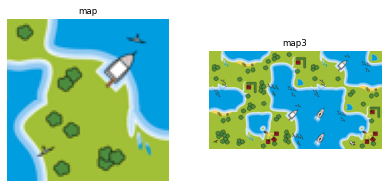

In [ ]:
import os
from PIL import Image

import matplotlib.pyplot as plt


def lade_kacheln(ordner, groesse):
    kacheln = {}
    for name in os.listdir(ordner):
        if name.startswith('tile') and name[5] == '_' and name != 'tileS_gray.png':
            bits = name[6:10]                      # z. B. '0001'
            bild = Image.open(os.path.join(ordner, name)).convert('RGB')
            kacheln[bits] = bild.resize((groesse, groesse))
    return kacheln


def baue_bild(fertig, kacheln, groesse):
    reihen = len(fertig) // 2
    spalten = len(fertig[0]) // 2
    bild = Image.new('RGB', (spalten * groesse, reihen * groesse))
    for r in range(reihen):
        for c in range(spalten):
            bits = fertig[2 * r][2 * c] + fertig[2 * r][2 * c + 1] + fertig[2 * r + 1][2 * c] + fertig[2 * r + 1][2 * c + 1]
            bild.paste(kacheln[bits], (c * groesse, r * groesse))
    return bild


kacheln = lade_kacheln('beispieldaten/kacheln', 40)
print(len(kacheln), 'Kachelbilder geladen:', sorted(kacheln))

plt.figure(figsize=(7, 3))
for nr, name in enumerate(['map', 'map3']):
    plt.subplot(1, 2, nr + 1)
    plt.imshow(baue_bild(ergebnisse[name], kacheln, 40))
    plt.title(name, fontsize=9)
    plt.axis('off')
plt.show()

Wasser und Land treffen an allen Kanten so zusammen, dass kein Sprung zu sehen ist.